# Exercise: linear algebra with `numpy.linalg`

## Introduction

`numpy.linalg` provides the classical linear algebra tools: products, norms, determinants, inverses, linear system solvers, least-squares, eigenvalues...

The steps are:

1. Manipulate vectors and matrices: products, transpose, norm, determinant, with a 2D rotation as example
2. Solve linear systems with `inv`, `solve`, `lstsq` and `pinv` to recover the composition of a mixture from its absorption spectrum
3. Play with eigenvalues and eigenvectors (`eig`, `eigh`) to find the principal axes of a cloud of points

Useful documentation: https://numpy.org/doc/stable/reference/routines.linalg.html

## Part 0: basics

In [23]:
import numpy as np
%matplotlib widget
# This requires ipympl
# Or for non-interactive plots: %matplotlib inline

from matplotlib import pyplot as plt

### Matrix product

In numpy, a vector is a 1D array and a matrix is a 2D array.

In [25]:
v = np.array([1., 2., 3.])

M = np.array([[4., 1., 0.],
              [2., 3., 0.],
              [1., 1., 1.]])

Compute:

* `M * v` (element-wise product with broadcasting)
* `M @ v` (matrix-vector product, same as `np.dot(M, v)`)
* `v @ v` (dot product)

What is the difference between `M * v` and `M @ v`?

In [26]:
elementwise = M * v
product = M @ v
dot = v @ v
print("M * v =\n", elementwise)
print("M @ v =", product)
print("v @ v =", dot)

M * v =
 [[4. 2. 0.]
 [2. 6. 0.]
 [1. 2. 3.]]
M @ v = [6. 8. 6.]
v @ v = 14.0


### Transpose, norm, determinant, rank

Compute:

* the transpose of `M` (hint: `.T`)
* two ways of computing the norm of `v` (hint: `np.linalg.norm` is one), and check you get the same result with both.
* the determinant of `M` (hint: `np.linalg.det`)

In [28]:
M_transpose = M.T
v_norm_1 = np.linalg.norm(v)
v_norm_2 = np.sqrt(v@v)
M_det = np.linalg.det(M)
print("transpose:\n", M_transpose)
print("norm:", v_norm_1, v_norm_2)
print("det:", M_det)

transpose:
 [[4. 2. 1.]
 [1. 3. 1.]
 [0. 0. 1.]]
norm: 3.7416573867739413 3.7416573867739413
det: 10.000000000000002


### A 2D rotation

The matrix of a rotation of angle $\theta$ in 2D is:

$$
R = \begin{pmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{pmatrix}
$$

Write a function `rotation(theta)` returning this matrix for an angle in radians.

In [3]:
def rotation(theta):
    return np.array([[np.cos(theta), -np.sin(theta)],[np.sin(theta), np.cos(theta)]])

The points of a shape are stored as a `(2, N)` array: first row is x, second row is y.

Rotate the shape by 30° (hint: `np.radians`) with a single matrix product (make sure you understand how the matrix product can work here in a single call).

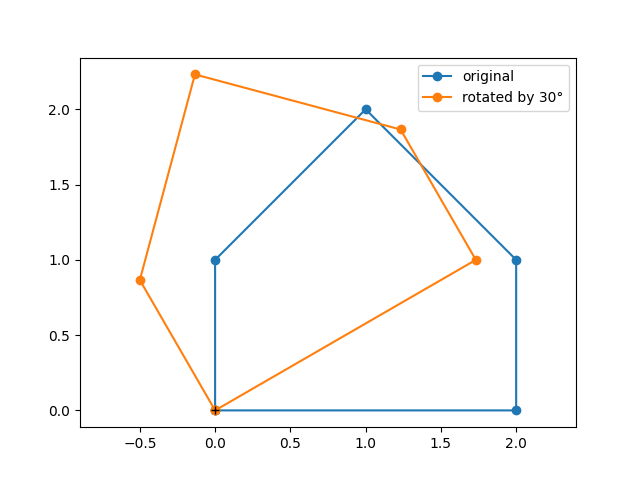

In [30]:
shape = np.array([[0., 2., 2., 1., 0., 0.],
                  [0., 0., 1., 2., 1., 0.]])

R = rotation(np.radians(30))
rotated = R @ shape

fig = plt.figure()
plt.plot(shape[0], shape[1], "o-", label="original")
plt.plot(rotated[0], rotated[1], "o-", label="rotated by 30°")
plt.plot(0, 0, "k+")
plt.axis("equal")
plt.legend()

## Part II: solving linear systems

A solution contains 3 compounds with unknown concentrations $c_1, c_2, c_3$.
Each compound $j$ absorbs light at wavelength $\lambda$ with a known spectrum $\varepsilon_j(\lambda)$.

According to the Beer-Lambert law, the absorbance of the mixture is the sum of the contributions of each compound:

$$
A(\lambda) = \sum_j \varepsilon_j(\lambda) \, c_j
$$

Measured at several wavelengths $\lambda_i$, this is a linear system $E \, c = a$, with:

* `E`: the matrix of the spectra, of shape (number of wavelengths, 3), one column per compound
* `c`: the vector of the 3 unknown concentrations
* `a`: the measured absorbance at each wavelength

The goal is to recover `c` from `a`.

### The data

The following cell simulates the spectra of the compounds and a (noisy) measurement of the mixture.

E shape: (61, 3) absorbance shape: (61,)


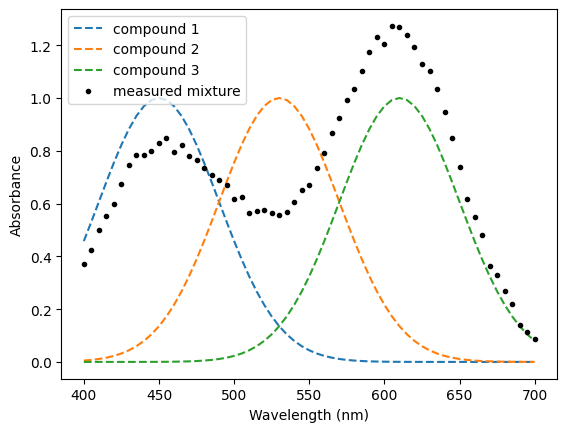

In [7]:
wavelengths = np.linspace(400, 700, 61)  # in nm
centers = np.array([450, 530, 610])  # in nm

# One gaussian spectrum per compound, one column per compound
E = np.exp(-0.5 * ((wavelengths[:, np.newaxis] - centers) / 40) ** 2)

true_c = np.array([0.8, 0.3, 1.2])
rng = np.random.default_rng(seed=0)
absorbance = E @ true_c + rng.normal(scale=0.02, size=len(wavelengths))

print("E shape:", E.shape, "absorbance shape:", absorbance.shape)

fig = plt.figure()
for j in range(3):
    plt.plot(wavelengths, E[:, j], "--", label=f"compound {j + 1}")
plt.plot(wavelengths, absorbance, "k.", label="measured mixture")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Absorbance")
plt.legend()

### Square system: 3 equations, 3 unknowns

Suppose we only have 3 measurements at the 3 wavelengths 450, 530 and 610 nm (indices (10, 26, 42) in the `wavelengths` array).

In [11]:
selection = [10,26,42]
E3 = E[selection]
a3 = absorbance[selection]
print("E3 shape:", E3.shape, "a3 shape:", a3.shape)
print("E3:", E3)

E3 shape: (3, 3) a3 shape: (3,)
E3: [[1.00000000e+00 1.35335283e-01 3.35462628e-04]
 [1.35335283e-01 1.00000000e+00 1.35335283e-01]
 [3.35462628e-04 1.35335283e-01 1.00000000e+00]]


Solve $E_3 \, c = a_3$:

1. by computing the inverse of `E3` (hint: `np.linalg.inv`)
2. with `np.linalg.solve`

Check that both results are the same, and compare them with `true_c`.

inv:   [0.78988828 0.28253526 1.2292845 ]
solve: [0.78988828 0.28253526 1.2292845 ]
true:  [0.8 0.3 1.2]


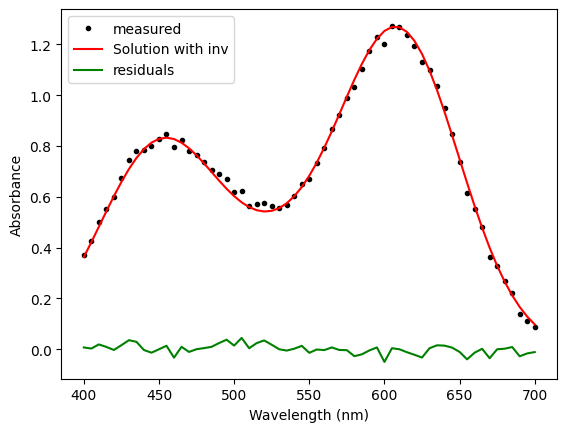

In [ ]:
c_inv = np.linalg.inv(E3) @ a3
c_solve = np.linalg.solve(E3,a3)
print("inv:  ", c_inv)
print("solve:", c_solve)
print("true: ", true_c)

fig = plt.figure()
plt.plot(wavelengths, absorbance, "k.", label="measured")
plt.plot(wavelengths, E @ c_inv, "r", label="Solution with inv")
plt.plot(wavelengths, absorbance - E @ c_inv, "g", label="residuals")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Absorbance")
plt.legend()

Note: `solve` is faster and numerically more accurate than computing the inverse: prefer it when the inverse itself is not needed.

The result is not exactly `true_c` because the measurement is noisy, and only 3 measurements out of 61 were used...

### Overdetermined system: 61 equations, 3 unknowns

With all the wavelengths, there are more equations than unknowns: `E` is not square and has no inverse.
There is in general no exact solution, but we can find the `c` that minimizes the squared error $\| E \, c - a \|^2$: this is the **least-squares** solution.

Compute it:

1. with `np.linalg.lstsq` (use `rcond=None`), which returns a tuple: the solution is its first element
2. with the pseudo-inverse `np.linalg.pinv`
3. with the *normal equations*: $c = (E^T E)^{-1} E^T a$

In [14]:
c_lstsq = np.linalg.lstsq(E,absorbance,rcond=None) # TODO
c_pinv = np.linalg.pinv(E) @ absorbance
c_normal = (np.linalg.inv(E.T @ E) @ E.T) @ absorbance
print("lstsq: ", c_lstsq)
print("pinv:  ", c_pinv)
print("normal:", c_normal)
print("true:  ", true_c)

lstsq:  (array([0.79592422, 0.29536867, 1.21373349]), array([0.01684036]), np.int32(3), array([4.64478932, 3.70038532, 2.61097227]))
pinv:   [0.79592422 0.29536867 1.21373349]
normal: [0.79592422 0.29536867 1.21373349]
true:   [0.8 0.3 1.2]


Compute the error (norm of the difference with `true_c`) of the square-system solution and of the least-squares solution. Which one is better?

error square: 0.035564668163136796 error lstsq: 0.015055559234854604


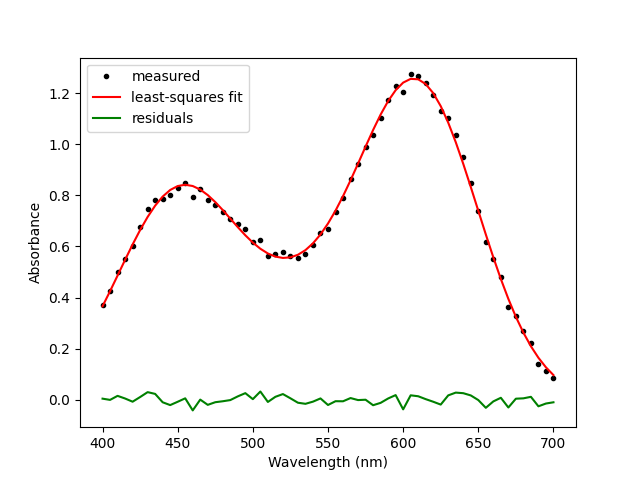

In [31]:
error_square = np.linalg.norm(c_inv - true_c)
error_lstsq = np.linalg.norm(c_lstsq[0] - true_c)
print("error square:", error_square, "error lstsq:", error_lstsq)

fig = plt.figure()
plt.plot(wavelengths, absorbance, "k.", label="measured")
plt.plot(wavelengths, E @ c_lstsq[0], "r", label="least-squares fit")
plt.plot(wavelengths, absorbance - E @ c_lstsq[0], "g", label="residuals")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Absorbance")
plt.legend()

### Bonus: ill-conditioned system

The *condition number* (`np.linalg.cond`) measures how much the errors on `a` can be amplified on the solution `c`.

Redo the least-squares fit (`np.linalg.lstsq()`) with the 3 spectra centered at 520, 530 and 540 nm (indices (24,26,28) in `wavelengths` array), which are very similar to each other.

* Compare the condition numbers of both `E` matrices.
* Compare the errors on `c`.

In [20]:
selection = [24,26,28]
E_close = E[selection]
absorbance_close = E_close @ true_c + rng.normal(scale=0.02, size=len(selection))
c_close = np.linalg.lstsq(E_close, absorbance_close, rcond=None)[0]  # TODO
print("cond E:", np.linalg.cond(E), "cond E_close:", np.linalg.cond(E_close))
print("solution:", c_close, "true:", true_c)

cond E: 1.7789500759018322 cond E_close: 89.67854938543002
solution: [1.6236994  0.05268388 1.99288301] true: [0.8 0.3 1.2]


## Part III: eigenvalues and eigenvectors

An eigenvector $v$ of a square matrix $A$ is a non-zero vector whose direction is unchanged by $A$:

$$
A \, v = \lambda \, v
$$

where $\lambda$ is the associated eigenvalue.

### Eigenvalues of a matrix

Compute the eigenvalues and eigenvectors of `M` (hint: `np.linalg.eig`).

The eigenvectors are the **columns** of the returned matrix.
Check that $M \, v = \lambda \, v$ for each of them.

In [33]:
eigenvalues, eigenvectors = np.linalg.eig(M)
print("eigenvalues:", eigenvalues)
print("eigenvectors:", eigenvectors)
print("Verification:", np.allclose(M @ eigenvectors, eigenvectors @ np.diag(eigenvalues)))

eigenvalues: [1. 2. 5.]
eigenvectors: [[ 0.          0.40824829 -0.66666667]
 [ 0.         -0.81649658 -0.66666667]
 [ 1.         -0.40824829 -0.33333333]]
Verification: True


## Solution

<details><summary>...</summary>


```python
# Part I

import numpy as np

# Matrix product
elementwise = M * v  # Each row of M multiplied element-wise by v
product = M @ v
dot = v @ v

# Transpose, norm, determinant, rank
M_transpose = M.T
v_norm_1 = np.linalg.norm(v)
v_norm_2 = np.sqrt(v@v)
M_det = np.linalg.det(M)

# A 2D rotation
def rotation(theta):
    return np.array([[np.cos(theta), -np.sin(theta)],
                     [np.sin(theta), np.cos(theta)]])

rotated = R @ shape

# Part II

# Square system
selection = [10, 26,42]]
E3 = E[selection]
a3 = absorbance[selection]

c_inv = np.linalg.inv(E3) @ a3
c_solve = np.linalg.solve(E3, a3)

# Overdetermined system
c_lstsq = np.linalg.lstsq(E, absorbance, rcond=None)[0]
c_pinv = np.linalg.pinv(E) @ absorbance
c_normal = np.linalg.inv(E.T @ E) @ E.T @ absorbance

error_square = np.linalg.norm(c_solve - true_c)
error_lstsq = np.linalg.norm(c_lstsq - true_c)

# Bonus: ill-conditioned system
selection_2 = [24,26,28]
E_close = E[selection_2]
c_close = np.linalg.lstsq(E_close, absorbance_close, rcond=None)[0]

# Part III

# Eigenvalues of a matrix
eigenvalues, eigenvectors = np.linalg.eig(M)
for i in range(len(eigenvalues)):
    print(np.allclose(M @ eigenvectors[:, i], eigenvalues[i] * eigenvectors[:, i]))
# Or all at once with broadcasting: each column is multiplied by its eigenvalue
print(np.allclose(M @ eigenvectors, eigenvectors * eigenvalues))

```

</details>